# Time Series Forecasting with SARIMA, Prophet, and LSTM

This project investigates and benchmarks three time series analysis methods, predicting the Global_active_power based on historic data

# Exploratory analysis

In [2]:
# Let's start by loading the data and having a quick look at its content and datatypes.
import pandas as pd
from functions import getKaggleData

#getKaggleData() # Run this line to dowload the data if you haven't done so already.

path = "../data/household_power_consumption.txt"
data = pd.read_csv(path, sep=";", low_memory=False)

print(f"Data head:\n{data.head()}")
data.info()

Data head:
         Date      Time Global_active_power Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00               4.216                 0.418  234.840   
1  16/12/2006  17:25:00               5.360                 0.436  233.630   
2  16/12/2006  17:26:00               5.374                 0.498  233.290   
3  16/12/2006  17:27:00               5.388                 0.502  233.740   
4  16/12/2006  17:28:00               3.666                 0.528  235.680   

  Global_intensity Sub_metering_1 Sub_metering_2  Sub_metering_3  
0           18.400          0.000          1.000            17.0  
1           23.000          0.000          1.000            16.0  
2           23.000          0.000          2.000            17.0  
3           23.000          0.000          1.000            17.0  
4           15.800          0.000          1.000            17.0  
<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column      

# Part 1: Cleaning and preprocessing

In [3]:
# Fixing datatypes
for col in data.columns:
    if col not in ['Date', 'Time']:
        data[col] = pd.to_numeric(data[col], errors='coerce') # float64

data['DateTime'] = pd.to_datetime(data['Date'] + ' ' + data['Time'], format='%d/%m/%Y %H:%M:%S')

In [4]:
# Checking missing values
missing_values = data.isnull().sum()
print(f"Missing values per column:\n{missing_values}\n")

print(f"Percentage of missing values per column:\n{(data.isna().mean() * 100).map(lambda x: f'{x:.2f}%')}")

Missing values per column:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
DateTime                     0
dtype: int64

Percentage of missing values per column:
Date                     0.00%
Time                     0.00%
Global_active_power      1.25%
Global_reactive_power    1.25%
Voltage                  1.25%
Global_intensity         1.25%
Sub_metering_1           1.25%
Sub_metering_2           1.25%
Sub_metering_3           1.25%
DateTime                 0.00%
dtype: str


Having 2 075 259 rows, 1.25% NAs is manageable. Let's look at where they occour.

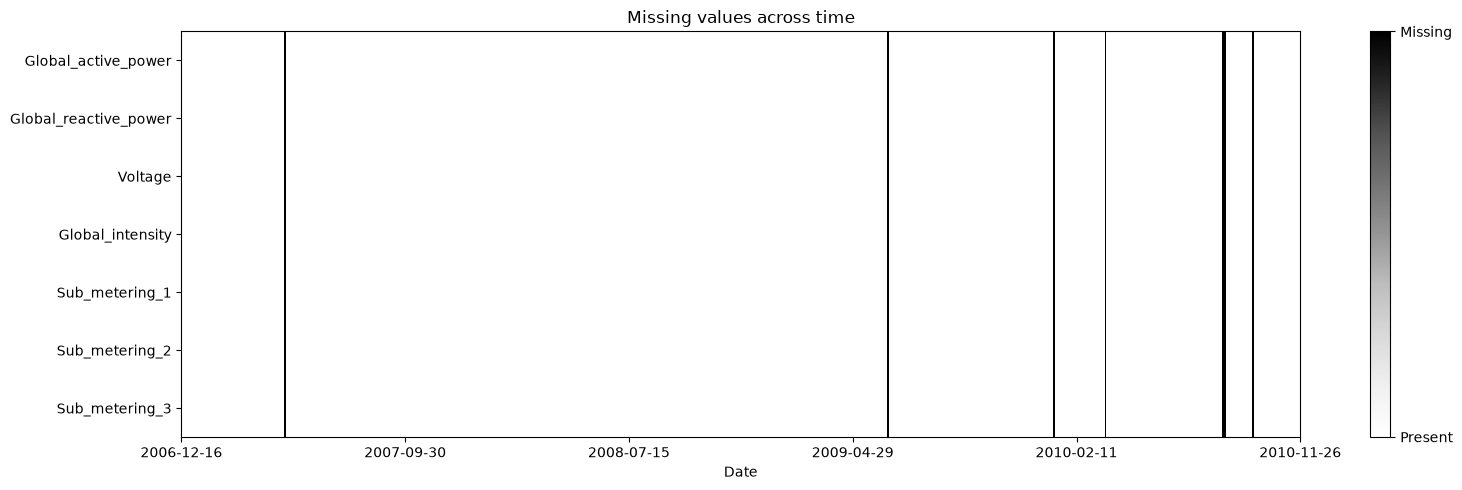

In [5]:
# Visualize missing values across the full timeline
import matplotlib.pyplot as plt
from functions import plot_na_heatmap

plot_na_heatmap(data)

Missing observations occur simultaneously across all measurement variables at several points in time, suggesting gaps in the recorded measurement data rather than isolated missing value. **For simplicity, we will use a simple fill forward imputation on the minute level**.

In [6]:
# Filling missing values using forward fill
data = data.ffill()
missing_values = data.isnull().sum()
print(f"Missing values per column:\n{missing_values}")

Missing values per column:
Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
DateTime                 0
dtype: int64


## Part 2: Split

The dataset contains power consumtion data for the dates below

In [7]:
# The dataset contains data from
print(f"Min date: {data['DateTime'].min()}")
print(f"Max date: {data['DateTime'].max()}")

Min date: 2006-12-16 17:24:00
Max date: 2010-11-26 21:02:00


Let's use all avaliable data up until 2010-10-31 as our training set, and have November of 2010 as our test set later on

In [8]:
# Define training set for exploration
train_data = data[data['DateTime'] < '2010-11-01']

## Part 3: Exploration

Now, a first look at the target variable "Global_active_power". Because of its noisyness at minute nad hour level, and because we intend to predict the power consumption on a daily level, we look at the daily data.

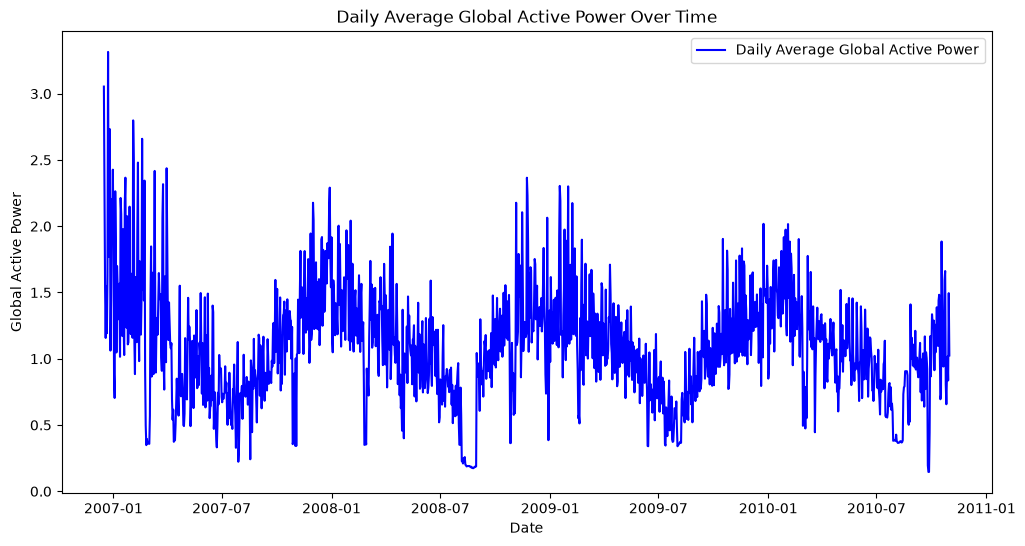

In [9]:
import matplotlib.pyplot as plt

daily_data = (
    train_data
    .set_index("DateTime")["Global_active_power"]
    .resample("D")
    .mean()
)

plt.figure(figsize=(12, 6))
plt.plot(daily_data.index, daily_data.values, label="Daily Average Global Active Power", color="blue")
plt.title("Daily Average Global Active Power Over Time")
plt.xlabel("Date")
plt.ylabel("Global Active Power")
plt.legend()
plt.show()

Aside from the obvious seasonality, the part of the curve right after 2008-07 drags our attention (also occurs two years later but in smaller scale). Initially we may suspect this is from the fill forward imputation, but there were no missing values here in the raw data. Let's take a closer look.

array([<Axes: xlabel='DateTime'>, <Axes: xlabel='DateTime'>,
       <Axes: xlabel='DateTime'>, <Axes: xlabel='DateTime'>,
       <Axes: xlabel='DateTime'>, <Axes: xlabel='DateTime'>], dtype=object)

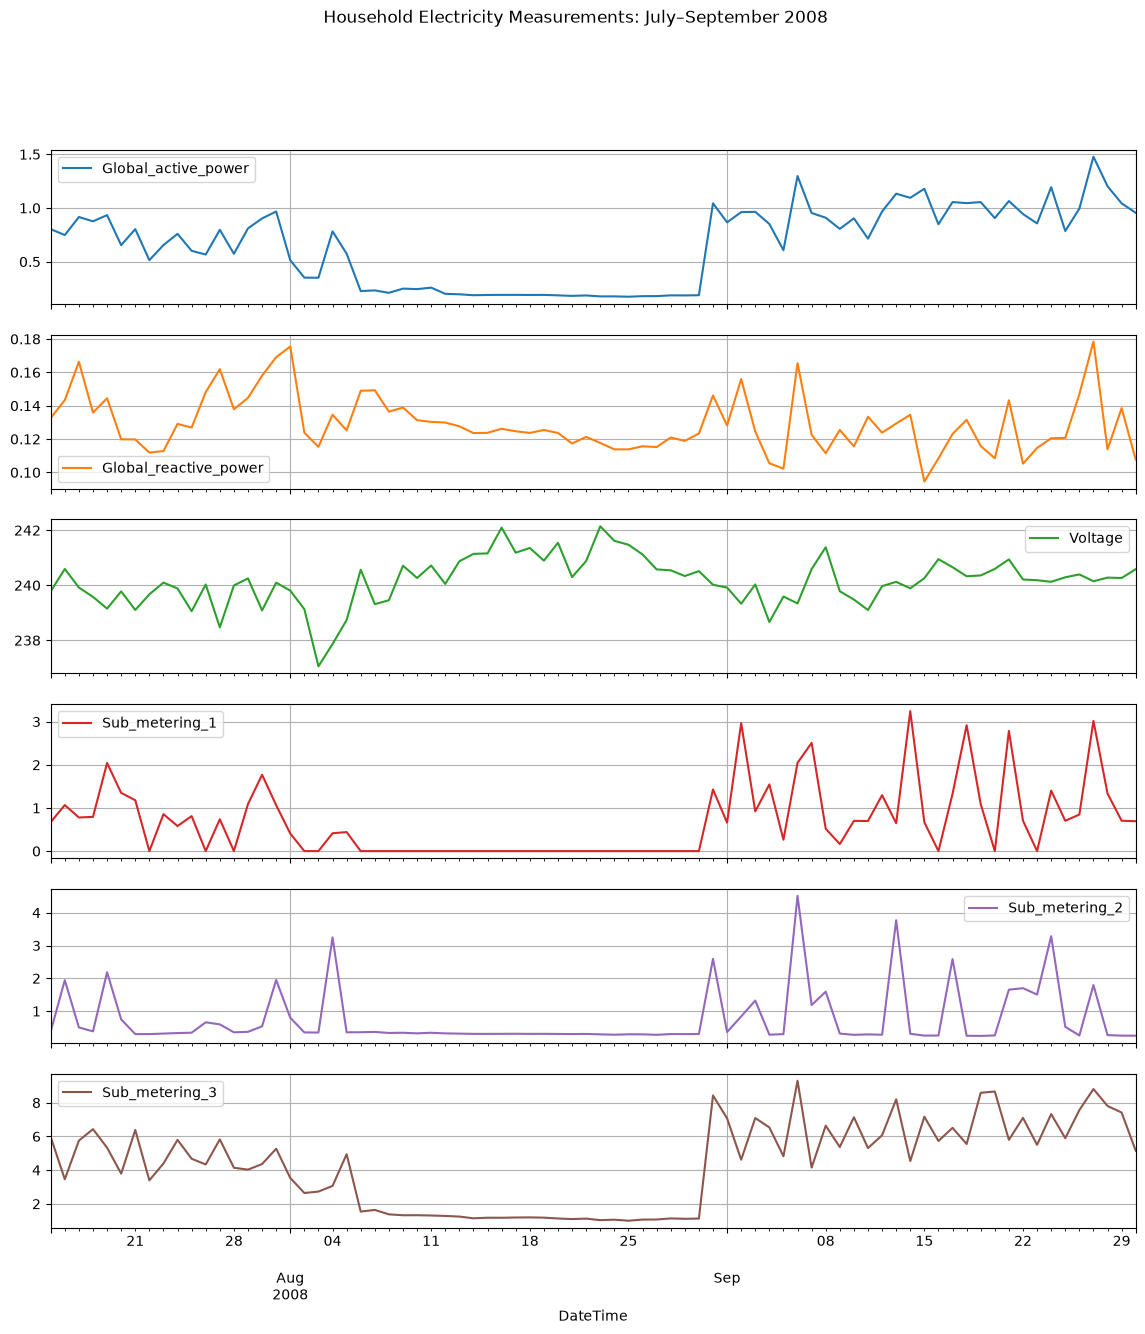

In [10]:
# Set DateTime as index
daily_variables = (
    train_data
    .set_index("DateTime")[
        [
            "Global_active_power",
            "Global_reactive_power",
            "Voltage",
            "Sub_metering_1",
            "Sub_metering_2",
            "Sub_metering_3"
        ]
    ]
    .resample("D")
    .mean()
)

# Select period
period = daily_variables.loc["2008-07-15":"2008-09-30"]

# Plot all variables
period.plot(
    subplots=True,
    figsize=(14, 14),
    sharex=True,
    title="Household Electricity Measurements: July–September 2008",
    grid=True,
    legend=True
)

Several measurements deviate significantly from their normal (volatile) behaviour:

- **Global_active_power:** Measures the total active power consumed by the household
- **Global_reactive_power:** Measures reactive power associated with electrical equipment
- **Voltage:** Measures the average voltage supplied to the household
- **Sub_metering_1:** Measures energy consumption by kitchen appliances
- **Sub_metering_2:** Measures energy consumption by the laundry room
- **Sub_metering_3:** Measures energy consumption by electric water heating and air conditioning

See documentation (https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption)

The measurements of electric power consumption come from one household (located in Sceaux, 7 km from Paris) The low and stable readings across active power and all three sub-meters may suggest that the household may have been unoccupied during this period, perhaps because the residents were on vacation. Some appliances may still have been plugged in, which could explain why some measurements does not drop to zero.

However, we can't know for sure and there is no documentation covering this avaliable on the internet. We will simply accept these measurements as valid, it is not a too long period after all.